# Stanford Cars Image Classification
## Clean Retraining & Portfolio Edition

**Project:** CSY3025 Artificial Intelligence Techniques — Stanford Cars image classification  
**Dataset:** 16,185 car images across 196 fine-grained classes  
**Models:** Basic CNN baseline + MobileNetV2 transfer learning  
**Target environment:** WSL2 · Python 3.13 · TensorFlow 2.21 · NVIDIA RTX 5070

---

### Purpose

This notebook recreates the original university project as a cleaner, reproducible, portfolio-ready ML pipeline.

The original project explored:

1. Stanford Cars dataset preparation
2. Dataset visualisation
3. Bounding-box cropping and preprocessing
4. Data augmentation
5. A basic CNN
6. MobileNetV2 transfer learning
7. Fine-tuning
8. Evaluation and predictions

### Main engineering changes

- **CHANGED:** original images are never renamed or moved.
- **CHANGED:** original train/test folders are combined logically through metadata.
- **ADDED:** deterministic seeds and persisted dataset splits.
- **CHANGED:** `tf.data` lazily loads images instead of storing the complete image dataset in RAM.
- **CHANGED:** images are decoded directly as RGB.
- **CHANGED:** preprocessing is embedded in each model to reduce training/deployment mismatch.
- **CHANGED:** MobileNetV2 uses a lightweight global-average-pooling head.
- **ADDED:** top-3 accuracy for the future Django demo.
- **ADDED:** checkpoints, per-class analysis, top confusion pairs and deployment artifacts.
- **ADDED:** all major plots are saved under `artifacts/figures/`.

> Historical metrics from the original technical report are shown only for comparison. The retrained model is evaluated again from scratch.

# 1. Environment and reproducibility

Run this notebook using the WSL interpreter:

`/home/sergiu/.venv/bin/python`

The RTX 5070 can print a message about PTX JIT compilation for compute capability `12.0a`. That is acceptable as long as the GPU appears below and TensorFlow operations run on `/GPU:0`.

This notebook intentionally does **not** enable XLA or `jit_compile=True`.

In [39]:
import gc
import json
import os
import platform
import random
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

# ADDED: one seed shared by Python, NumPy, TensorFlow and data splitting.
SEED = 42

# ADDED: reproducibility across the main random-number generators.
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ADDED: avoid TensorFlow reserving all GPU memory immediately.
gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        # CHANGED: memory growth must be configured before GPU initialization.
        pass

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("GPUs:", gpus)

# ADDED: fail immediately if VS Code accidentally uses the CPU-only Python.
assert gpus, (
    "No TensorFlow GPU detected. "
    "Select /home/sergiu/.venv/bin/python in VS Code."
)

Python executable: /home/sergiu/.venv/bin/python
Python version: 3.13.16
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ADDED: central experiment configuration.

IMAGE_SIZE = (224, 224)
NUM_CLASSES = 196
BATCH_SIZE = 32

BASELINE_EPOCHS = 50
HEAD_EPOCHS = 15
FINE_TUNE_EPOCHS = 20
FINE_TUNE_LAYERS = 20

# ADDED: keep the basic CNN for the portfolio comparison.
TRAIN_BASELINE = True

# ADDED: use staged MobileNetV2 fine-tuning.
RUN_FINE_TUNING = True

# CHANGED: optional tuner is disabled for the first clean retrain.
RUN_TUNER = False

# ADDED: one place for all project paths.
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"

# CHANGED: match the actual Stanford Cars folder structure.
TRAIN_SOURCE_DIR = DATA_DIR / "cars_train" / "cars_train"

# CHANGED: test images are stored directly inside data/cars_test.
TEST_SOURCE_DIR = DATA_DIR / "cars_test" / "cars_test"

ANNO_TRAIN_PATH = PROJECT_ROOT / "anno_train.csv"
ANNO_TEST_PATH = PROJECT_ROOT / "anno_test.csv"
NAMES_PATH = PROJECT_ROOT / "names.csv"

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
FIGURE_DIR = ARTIFACT_DIR / "figures"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Train images:", TRAIN_SOURCE_DIR)
print("Test images:", TEST_SOURCE_DIR)
print("Artifacts:", ARTIFACT_DIR)

Project root: /home/sergiu/projects/stanford-cars
Train images: /home/sergiu/projects/stanford-cars/data/cars_train/cars_train
Test images: /home/sergiu/projects/stanford-cars/data/cars_test/cars_test
Artifacts: /home/sergiu/projects/stanford-cars/artifacts


# 2. Methodology

## 2.1 Dataset selection

The project uses the **Stanford Cars** dataset with:

- 16,185 images,
- 196 fine-grained vehicle classes,
- bounding-box annotations,
- make/model/year-style class descriptions.

The source data contains separate train and test image folders.

The original university project merged those datasets and created a new stratified train/validation/test split. This regenerated notebook preserves that experimental design for comparability, but the merge happens **only in metadata**. No original image is renamed or moved.

## 2.2 Load annotations and class names

The annotation files have no header row, so their six fields are named explicitly.

Source class IDs are **1–196**. A separate zero-based label (`0–195`) is created for TensorFlow while preserving the source label unchanged.

In [41]:
ANNOTATION_COLUMNS = [
    "filename",
    "x1",
    "y1",
    "x2",
    "y2",
    "label",
]

# EXISTING CONCEPT: load Stanford Cars train/test annotations.
# CHANGED: source files remain untouched.
train_annotations = pd.read_csv(
    ANNO_TRAIN_PATH,
    header=None,
    names=ANNOTATION_COLUMNS,
)

test_annotations = pd.read_csv(
    ANNO_TEST_PATH,
    header=None,
    names=ANNOTATION_COLUMNS,
)

# EXISTING CONCEPT: load the 196 class descriptions.
class_names_df = pd.read_csv(
    NAMES_PATH,
    header=None,
    names=["class_name"],
)

print(f"Original train annotations: {len(train_annotations):,}")
print(f"Original test annotations:  {len(test_annotations):,}")
print(f"Class names:                {len(class_names_df):,}")

display(train_annotations.head())
display(class_names_df.head())

Original train annotations: 8,144
Original test annotations:  8,041
Class names:                196


,filename,x1,y1,x2,y2,label
0,00001.jpg,39,116,569,375,14
1,00002.jpg,36,116,868,587,3
2,00003.jpg,85,109,601,381,91
3,00004.jpg,621,393,1484,1096,134
4,00005.jpg,14,36,133,99,106


,class_name
0,AM General Hummer SUV 2000
1,Acura RL Sedan 2012
2,Acura TL Sedan 2012
3,Acura TL Type-S 2008
4,Acura TSX Sedan 2012


In [42]:
# ADDED: validate the source metadata before combining anything.

EXPECTED_TRAIN = 8_144
EXPECTED_TEST = 8_041
EXPECTED_TOTAL = 16_185
EXPECTED_CLASSES = 196

assert len(train_annotations) == EXPECTED_TRAIN
assert len(test_annotations) == EXPECTED_TEST
assert len(class_names_df) == EXPECTED_CLASSES

all_source_labels = pd.concat(
    [
        train_annotations["label"],
        test_annotations["label"],
    ],
    ignore_index=True,
)

assert all_source_labels.min() == 1
assert all_source_labels.max() == 196
assert all_source_labels.nunique() == EXPECTED_CLASSES

print("✓ Source metadata checks passed.")

✓ Source metadata checks passed.


### Add readable vehicle details

The original notebook parsed each class description into `brand`, `model`, `type`, and `year` for exploratory charts.

This version keeps that analysis. It also handles the three multi-word manufacturer prefixes present in the class list: **AM General, Aston Martin, and Land Rover**.

The `type` field still follows the original heuristic: the token immediately before the year is used as the type/trim token.

In [43]:
# ADDED: map the original 1-based IDs to readable class names.
class_names = class_names_df["class_name"].tolist()

class_id_to_name = {
    class_id: class_name
    for class_id, class_name in enumerate(
        class_names,
        start=1,
    )
}

# CHANGED: preserve the original parser idea while fixing known multi-word brands.
MULTIWORD_BRANDS = (
    "AM General",
    "Aston Martin",
    "Land Rover",
)

def parse_car_name(car_name):
    parts = car_name.split()

    # EXISTING CONCEPT: final token is year.
    year = parts[-1]

    # EXISTING CONCEPT: token before year is treated as type/trim.
    car_type = parts[-2]

    matched_brand = next(
        (
            brand
            for brand in MULTIWORD_BRANDS
            if car_name.startswith(brand + " ")
        ),
        None,
    )

    if matched_brand:
        brand_tokens = matched_brand.split()
        brand = matched_brand
        model = " ".join(
            parts[len(brand_tokens):-2]
        )
    else:
        brand = parts[0]
        model = " ".join(parts[1:-2])

    return brand, model, car_type, year

In [44]:
# CHANGED: combine metadata without physically merging image folders.

train_annotations = train_annotations.copy()
test_annotations = test_annotations.copy()

# ADDED: provenance is required because train/test filenames overlap.
train_annotations["source_split"] = "train"
test_annotations["source_split"] = "test"

# ADDED: create a globally unique application-friendly ID.
train_annotations["image_id"] = (
    "train_" + train_annotations["filename"].astype(str)
)
test_annotations["image_id"] = (
    "test_" + test_annotations["filename"].astype(str)
)

# CHANGED: derive image paths from the configured directories instead of
# hard-coding data/train and data/test.
train_annotations["relative_path"] = train_annotations["filename"].apply(
    lambda filename: str(
        (TRAIN_SOURCE_DIR / filename).relative_to(PROJECT_ROOT)
    )
)

# CHANGED: same approach for the original Stanford test images.
test_annotations["relative_path"] = test_annotations["filename"].apply(
    lambda filename: str(
        (TEST_SOURCE_DIR / filename).relative_to(PROJECT_ROOT)
    )
)

full_data = pd.concat(
    [
        train_annotations,
        test_annotations,
    ],
    ignore_index=True,
)

# EXISTING CONCEPT: add readable vehicle descriptions.
full_data["class_name"] = full_data["label"].map(
    class_id_to_name
)

parsed = full_data["class_name"].apply(
    parse_car_name
)

full_data[
    ["brand", "model", "type", "year"]
] = pd.DataFrame(
    parsed.tolist(),
    index=full_data.index,
)

# ADDED: TensorFlow/Keras uses 0-based class indices.
full_data["label_zero"] = (
    full_data["label"] - 1
)

print(f"Combined metadata rows: {len(full_data):,}")
display(full_data.head())

Combined metadata rows: 16,185


,filename,x1,y1,x2,y2,label,source_split,image_id,relative_path,class_name,brand,model,type,year,label_zero
0,00001.jpg,39,116,569,375,14,train,train_00001.jpg,data/cars_train/cars_train/00001.jpg,Audi TTS Coupe 2012,Audi,TTS,Coupe,2012,13
1,00002.jpg,36,116,868,587,3,train,train_00002.jpg,data/cars_train/cars_train/00002.jpg,Acura TL Sedan 2012,Acura,TL,Sedan,2012,2
2,00003.jpg,85,109,601,381,91,train,train_00003.jpg,data/cars_train/cars_train/00003.jpg,Dodge Dakota Club Cab 2007,Dodge,Dakota Club,Cab,2007,90
3,00004.jpg,621,393,1484,1096,134,train,train_00004.jpg,data/cars_train/cars_train/00004.jpg,Hyundai Sonata Hybrid Sedan 2012,Hyundai,Sonata Hybrid,Sedan,2012,133
4,00005.jpg,14,36,133,99,106,train,train_00005.jpg,data/cars_train/cars_train/00005.jpg,Ford F-450 Super Duty Crew Cab 2012,Ford,F-450 Super Duty Crew,Cab,2012,105


In [45]:
# ADDED: combined metadata integrity checks.

assert len(full_data) == EXPECTED_TOTAL
assert full_data["image_id"].is_unique
assert full_data["label"].nunique() == EXPECTED_CLASSES
assert full_data["label_zero"].min() == 0
assert full_data["label_zero"].max() == 195
assert full_data["class_name"].isna().sum() == 0

required_columns = [
    "filename",
    "x1",
    "y1",
    "x2",
    "y2",
    "label",
    "label_zero",
    "source_split",
    "image_id",
    "relative_path",
    "class_name",
]

assert (
    full_data[required_columns]
    .isna()
    .sum()
    .sum()
    == 0
)

print("✓ Combined metadata checks passed.")
print("Images:", len(full_data))
print("Classes:", full_data["label"].nunique())
print(
    "0-based label range:",
    full_data["label_zero"].min(),
    "-",
    full_data["label_zero"].max(),
)

✓ Combined metadata checks passed.
Images: 16185
Classes: 196
0-based label range: 0 - 195


### Verify physical image files

This is the first major safety improvement over the original workflow.

Instead of renaming and moving images, every metadata row is checked against its original location. If this cell fails, correct the folder path before doing any training.

In [46]:
# ADDED: build runtime absolute paths without persisting them as deployment metadata.
full_data["absolute_path"] = (
    full_data["relative_path"]
    .apply(
        lambda value: str(
            PROJECT_ROOT / value
        )
    )
)

file_exists = full_data[
    "absolute_path"
].map(
    lambda value: Path(value).exists()
)

missing_files = full_data.loc[
    ~file_exists
].copy()

print(f"Images found:   {file_exists.sum():,}")
print(f"Missing images: {len(missing_files):,}")

if len(missing_files):
    display(
        missing_files[
            [
                "image_id",
                "filename",
                "source_split",
                "relative_path",
            ]
        ].head(20)
    )

assert len(missing_files) == 0, (
    "Some images are missing. "
    "Check DATA_DIR, TRAIN_SOURCE_DIR and TEST_SOURCE_DIR."
)

print("✓ All 16,185 image files are present.")

Images found:   16,185
Missing images: 0
✓ All 16,185 image files are present.


## 2.3 Data visualisation

The original project explored distributions by:

- brand,
- model,
- type,
- year.

Those charts are retained, and new visualisations are added for:

- all 196 class counts,
- source bounding boxes,
- final train/validation/test sizes.

Every figure is saved to `artifacts/figures/` for future portfolio use.

In [47]:
# ADDED: save each figure automatically for the portfolio case study.
def save_and_show_figure(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / filename,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()


# CHANGED: plot precomputed counts for predictable ordering and readability.
def plot_category_counts(
    df,
    column,
    title,
    limit=None,
):
    counts = df[column].value_counts()

    if limit is not None:
        counts = counts.head(limit)

    plt.figure(
        figsize=(
            12,
            max(5, len(counts) * 0.28),
        )
    )

    sns.barplot(
        x=counts.values,
        y=counts.index.astype(str),
        orient="h",
    )

    plt.title(title)
    plt.xlabel("Images")
    plt.ylabel(column.capitalize())

    return counts

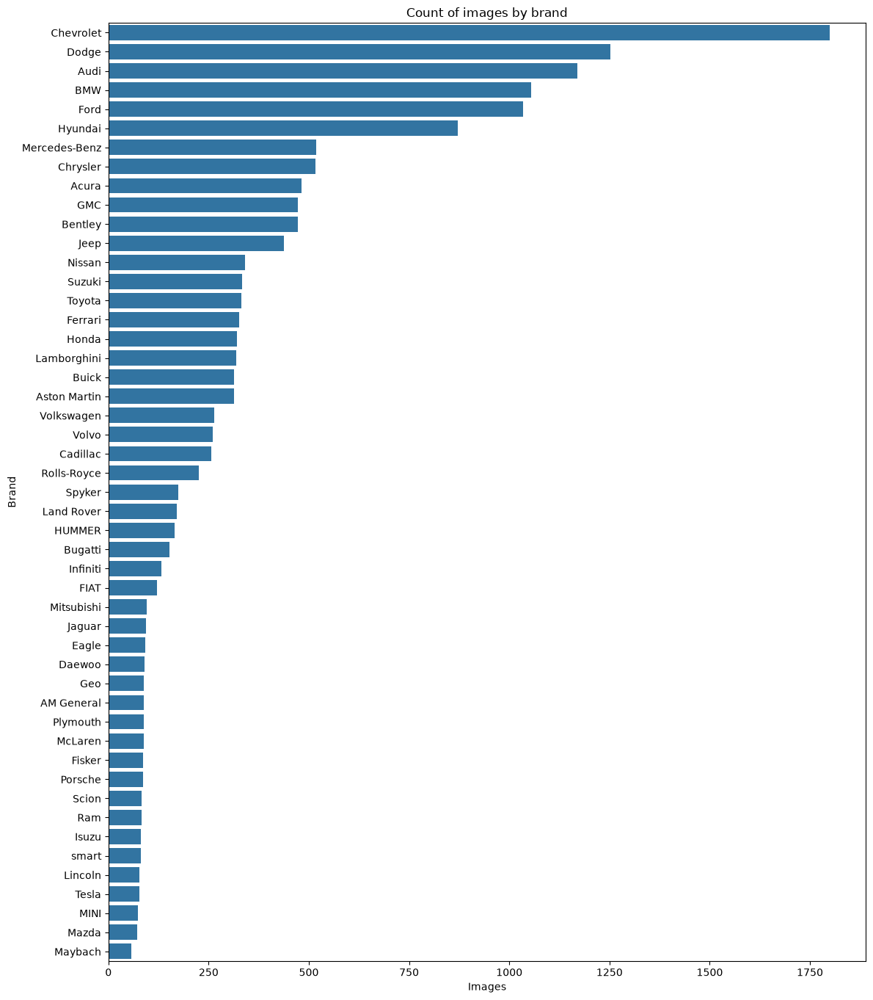

In [48]:
# EXISTING CONCEPT: brand distribution.
brand_counts = plot_category_counts(
    full_data,
    "brand",
    "Count of images by brand",
)

save_and_show_figure(
    "brand_distribution.png"
)

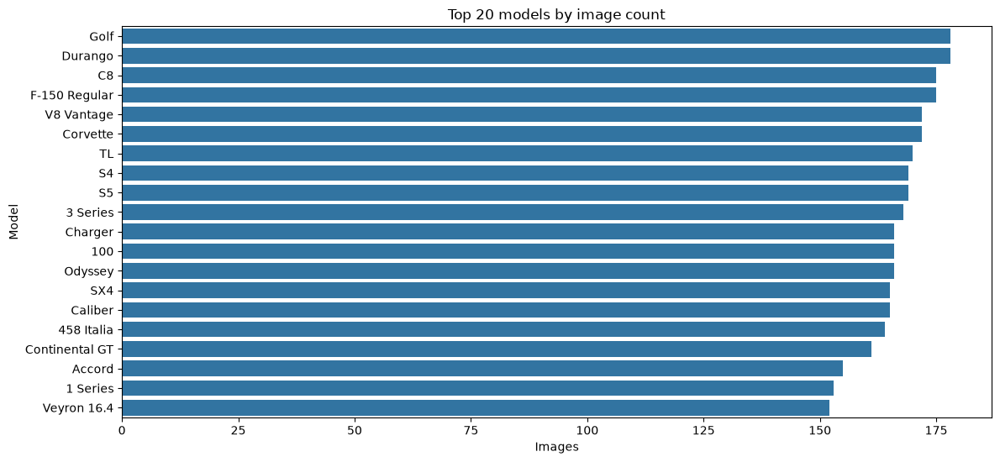

In [49]:
# EXISTING CONCEPT: top 20 model names for readability.
model_counts = plot_category_counts(
    full_data,
    "model",
    "Top 20 models by image count",
    limit=20,
)

save_and_show_figure(
    "top_20_models.png"
)

In [ ]:
# EXISTING CONCEPT: type/trim distribution.
type_counts = plot_category_counts(
    full_data,
    "type",
    "Count of images by type / trim token",
)

save_and_show_figure(
    "type_distribution.png"
)

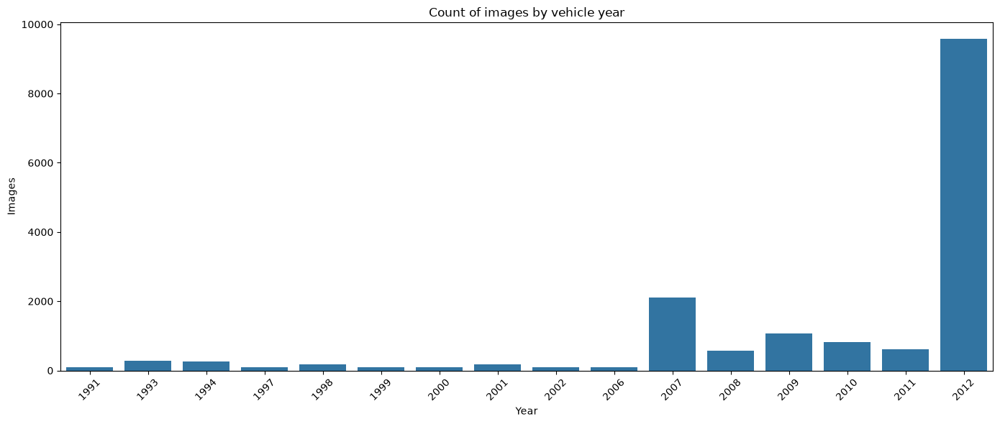

In [50]:
# EXISTING CONCEPT: year distribution.
year_counts = (
    full_data["year"]
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 6))

sns.barplot(
    x=year_counts.index.astype(str),
    y=year_counts.values,
)

plt.title("Count of images by vehicle year")
plt.xlabel("Year")
plt.ylabel("Images")
plt.xticks(rotation=45)

save_and_show_figure(
    "year_distribution.png"
)

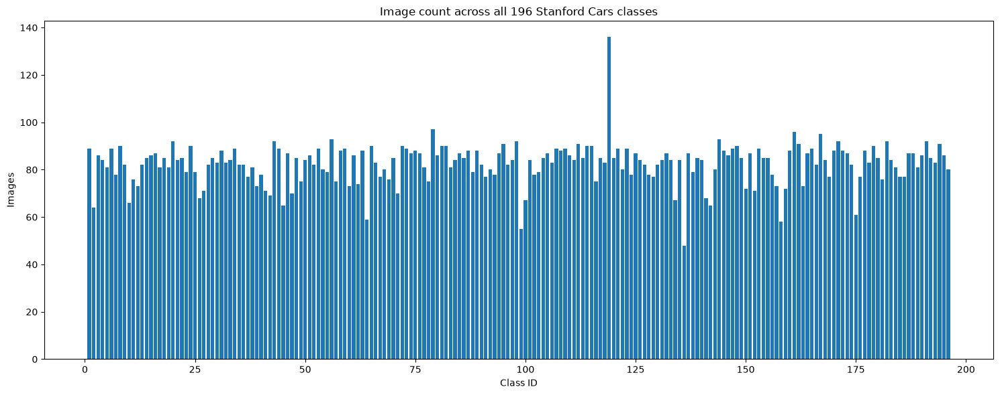

,images_per_class
count,196.000000
mean,82.576531
std,8.690063
min,48.000000
25%,78.750000
50%,84.000000
75%,88.000000
max,136.000000


In [52]:
# ADDED: class-balance view across all 196 fine-grained classes.
class_counts = (
    full_data
    .groupby(
        ["label", "class_name"]
    )
    .size()
    .reset_index(name="images")
    .sort_values("label")
)

plt.figure(figsize=(15, 6))

plt.bar(
    class_counts["label"],
    class_counts["images"],
)

plt.title(
    "Image count across all 196 Stanford Cars classes"
)
plt.xlabel("Class ID")
plt.ylabel("Images")

save_and_show_figure(
    "class_distribution_196.png"
)

display(
    class_counts["images"]
    .describe()
    .to_frame("images_per_class")
)

### Visual check: original images and bounding boxes

The classifier is trained on the annotated car region rather than the full image.

This cell visualises the exact source bounding boxes before preprocessing.

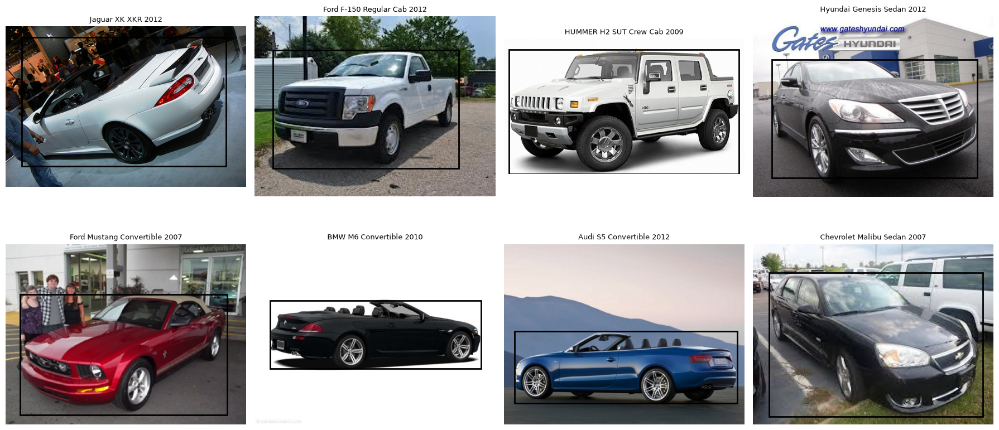

In [53]:
def read_rgb_image(path):
    # CHANGED: OpenCV reads BGR, so convert to RGB immediately.
    image = cv2.imread(str(path))

    if image is None:
        raise FileNotFoundError(path)

    return cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB,
    )


def show_raw_images_with_boxes(
    df,
    num=8,
    seed=SEED,
):
    sample = (
        df.sample(
            n=num,
            random_state=seed,
        )
        .reset_index(drop=True)
    )

    cols = 4
    rows = int(
        np.ceil(num / cols)
    )

    plt.figure(
        figsize=(18, rows * 4.5)
    )

    for i, row in sample.iterrows():
        image = read_rgb_image(
            PROJECT_ROOT
            / row["relative_path"]
        )

        ax = plt.subplot(
            rows,
            cols,
            i + 1,
        )

        ax.imshow(image)

        # EXISTING CONCEPT: use Stanford's x1/y1/x2/y2 annotation.
        rectangle = plt.Rectangle(
            (
                row["x1"],
                row["y1"],
            ),
            row["x2"] - row["x1"],
            row["y2"] - row["y1"],
            fill=False,
            linewidth=2,
        )

        ax.add_patch(rectangle)
        ax.set_title(
            row["class_name"],
            fontsize=9,
        )
        ax.axis("off")

    save_and_show_figure(
        "raw_images_with_bounding_boxes.png"
    )


show_raw_images_with_boxes(
    full_data
)

## 2.4 Reproducible train / validation / test split

The original notebook used two stratified `train_test_split` calls:

1. 10% of the combined dataset becomes test data.
2. 25% of the remaining 90% becomes validation data.

That produces approximately:

- **67.5% training**
- **22.5% validation**
- **10% testing**

The same logic and seed are retained for comparability.

Unlike the original notebook, images are **not moved** into new directories. The split is represented by metadata and exported to CSV.

In [54]:
from sklearn.model_selection import train_test_split

# EXISTING CONCEPT: same two-stage stratified split as the original project.
train_val_data, test_data = train_test_split(
    full_data,
    test_size=0.10,
    stratify=full_data["label"],
    random_state=SEED,
)

train_data, val_data = train_test_split(
    train_val_data,
    test_size=0.25,
    stratify=train_val_data["label"],
    random_state=SEED,
)

# ADDED: reset indices so prediction ordering is explicit later.
train_data = train_data.reset_index(
    drop=True
)
val_data = val_data.reset_index(
    drop=True
)
test_data = test_data.reset_index(
    drop=True
)

print(
    f"Train:      {len(train_data):,} "
    f"({len(train_data) / len(full_data):.1%})"
)
print(
    f"Validation: {len(val_data):,} "
    f"({len(val_data) / len(full_data):.1%})"
)
print(
    f"Test:       {len(test_data):,} "
    f"({len(test_data) / len(full_data):.1%})"
)

print()
print(
    "Train classes:",
    train_data["label"].nunique(),
)
print(
    "Validation classes:",
    val_data["label"].nunique(),
)
print(
    "Test classes:",
    test_data["label"].nunique(),
)

# ADDED: every split must contain all 196 classes.
assert (
    train_data["label"].nunique()
    == NUM_CLASSES
)
assert (
    val_data["label"].nunique()
    == NUM_CLASSES
)
assert (
    test_data["label"].nunique()
    == NUM_CLASSES
)

Train:      10,924 (67.5%)
Validation: 3,642 (22.5%)
Test:       1,619 (10.0%)

Train classes: 196
Validation classes: 196
Test classes: 196


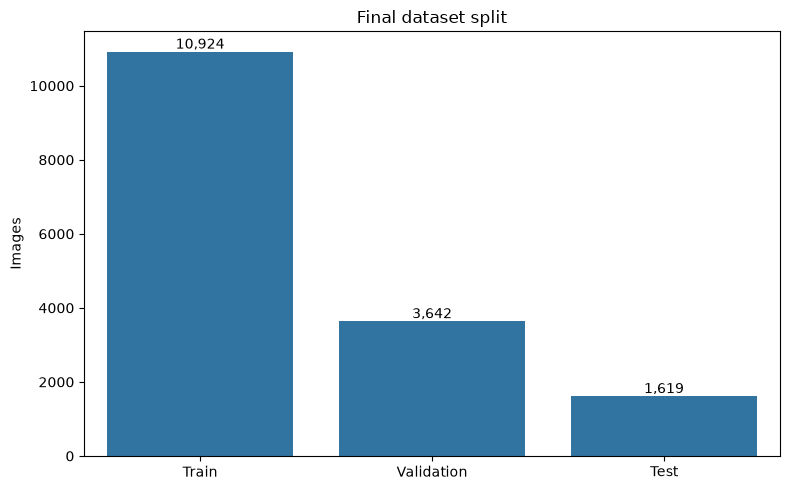

,split,images
0,Train,10924
1,Validation,3642
2,Test,1619


In [55]:
# ADDED: save the exact split used by the experiment and future Django demo.
SPLIT_COLUMNS = [
    "image_id",
    "filename",
    "source_split",
    "relative_path",
    "x1",
    "y1",
    "x2",
    "y2",
    "label",
    "label_zero",
    "class_name",
    "brand",
    "model",
    "type",
    "year",
]

train_data[
    SPLIT_COLUMNS
].to_csv(
    ARTIFACT_DIR
    / "train_split.csv",
    index=False,
)

val_data[
    SPLIT_COLUMNS
].to_csv(
    ARTIFACT_DIR
    / "val_split.csv",
    index=False,
)

test_data[
    SPLIT_COLUMNS
].to_csv(
    ARTIFACT_DIR
    / "test_split.csv",
    index=False,
)

split_sizes = pd.DataFrame(
    {
        "split": [
            "Train",
            "Validation",
            "Test",
        ],
        "images": [
            len(train_data),
            len(val_data),
            len(test_data),
        ],
    }
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=split_sizes,
    x="split",
    y="images",
)

plt.title("Final dataset split")
plt.xlabel("")
plt.ylabel("Images")

for index, row in split_sizes.iterrows():
    plt.text(
        index,
        row["images"] + 80,
        f'{row["images"]:,}',
        ha="center",
    )

save_and_show_figure(
    "dataset_split.png"
)

display(split_sizes)

## 2.5 Image preprocessing with `tf.data`

The original notebook loaded every cropped/resized image into NumPy arrays.

This version uses a lazy `tf.data` pipeline:

1. read a file only when a batch needs it,
2. decode JPEG directly as RGB,
3. crop using the Stanford bounding box,
4. resize to 224×224,
5. retain pixel values in the 0–255 range,
6. one-hot encode the 0-based label.

Model-specific scaling happens **inside the model**. This makes the final `.keras` artifact safer to deploy because the model owns its input scaling.

In [56]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_crop_resize(
    path,
    bbox,
    label_zero,
):
    # CHANGED: TensorFlow decodes directly into RGB.
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_jpeg(
        image_bytes,
        channels=3,
    )

    image_shape = tf.shape(image)
    height = image_shape[0]
    width = image_shape[1]

    x1, y1, x2, y2 = tf.unstack(
        tf.cast(
            bbox,
            tf.int32,
        )
    )

    # ADDED: defensive clipping guarantees a non-empty crop.
    x1 = tf.clip_by_value(
        x1,
        0,
        width - 1,
    )
    y1 = tf.clip_by_value(
        y1,
        0,
        height - 1,
    )
    x2 = tf.clip_by_value(
        x2,
        x1 + 1,
        width,
    )
    y2 = tf.clip_by_value(
        y2,
        y1 + 1,
        height,
    )

    # EXISTING CONCEPT: focus training on the annotated car region.
    image = image[
        y1:y2,
        x1:x2,
        :,
    ]

    # EXISTING CONCEPT: resize to MobileNetV2's 224×224 input geometry.
    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        antialias=True,
    )

    # CHANGED: keep 0–255 floats here.
    # Scaling is embedded inside each model.
    image = tf.cast(
        image,
        tf.float32,
    )

    # EXISTING CONCEPT: categorical cross-entropy uses one-hot labels.
    label = tf.one_hot(
        tf.cast(
            label_zero,
            tf.int32,
        ),
        depth=NUM_CLASSES,
        dtype=tf.float32,
    )

    return image, label


def make_dataset(
    df,
    training=False,
):
    absolute_paths = (
        df["relative_path"]
        .apply(
            lambda relative_path: str(
                PROJECT_ROOT
                / relative_path
            )
        )
        .to_numpy()
    )

    bboxes = (
        df[
            ["x1", "y1", "x2", "y2"]
        ]
        .astype(np.int32)
        .to_numpy()
    )

    labels = (
        df["label_zero"]
        .astype(np.int32)
        .to_numpy()
    )

    dataset = (
        tf.data.Dataset
        .from_tensor_slices(
            (
                absolute_paths,
                bboxes,
                labels,
            )
        )
    )

    if training:
        # ADDED: seeded shuffle with reshuffling between epochs.
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        decode_crop_resize,
        num_parallel_calls=AUTOTUNE,
    )

    # CHANGED: use the final partial batch rather than dropping images.
    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset


train_ds = make_dataset(
    train_data,
    training=True,
)

val_ds = make_dataset(
    val_data,
    training=False,
)

test_ds = make_dataset(
    test_data,
    training=False,
)

sample_images, sample_labels = next(
    iter(
        train_ds.take(1)
    )
)

print(
    "Image batch:",
    sample_images.shape,
    sample_images.dtype,
)
print(
    "Label batch:",
    sample_labels.shape,
    sample_labels.dtype,
)
print(
    "Pixel range:",
    float(
        tf.reduce_min(sample_images)
    ),
    "to",
    float(
        tf.reduce_max(sample_images)
    ),
)

W0000 00:00:1791330766.865009   12467 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791330766.963097   12467 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9218 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:02:00.0, compute capability: 12.0a


Image batch: (32, 224, 224, 3) <dtype: 'float32'>
Label batch: (32, 196) <dtype: 'float32'>
Pixel range: 0.0 to 255.00006103515625


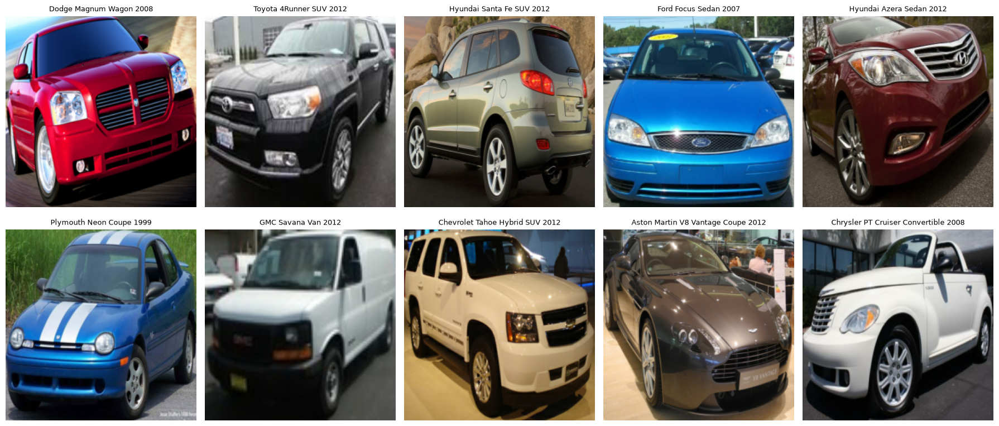

In [57]:
# ADDED: visual check of the exact cropped tensors entering the models.
def show_cropped_batch(
    images,
    labels,
    num=10,
    filename="processed_cropped_samples.png",
):
    num = min(
        num,
        len(images),
    )

    cols = 5
    rows = int(
        np.ceil(num / cols)
    )

    plt.figure(
        figsize=(18, rows * 4)
    )

    for i in range(num):
        label_index = int(
            tf.argmax(
                labels[i]
            ).numpy()
        )

        ax = plt.subplot(
            rows,
            cols,
            i + 1,
        )

        ax.imshow(
            tf.cast(
                images[i],
                tf.uint8,
            )
        )

        ax.set_title(
            class_names[
                label_index
            ],
            fontsize=9,
        )

        ax.axis("off")

    save_and_show_figure(
        filename
    )


show_cropped_batch(
    sample_images,
    sample_labels,
)

## 2.6 Data augmentation

The original notebook used `ImageDataGenerator` with rotation, horizontal flipping and shear.

This regenerated version uses Keras preprocessing layers, which:

- execute as part of the training graph,
- automatically turn off during validation/inference,
- are included with the saved model.

Augmentation remains intentionally mild because fine-grained car classification depends on subtle visual details.

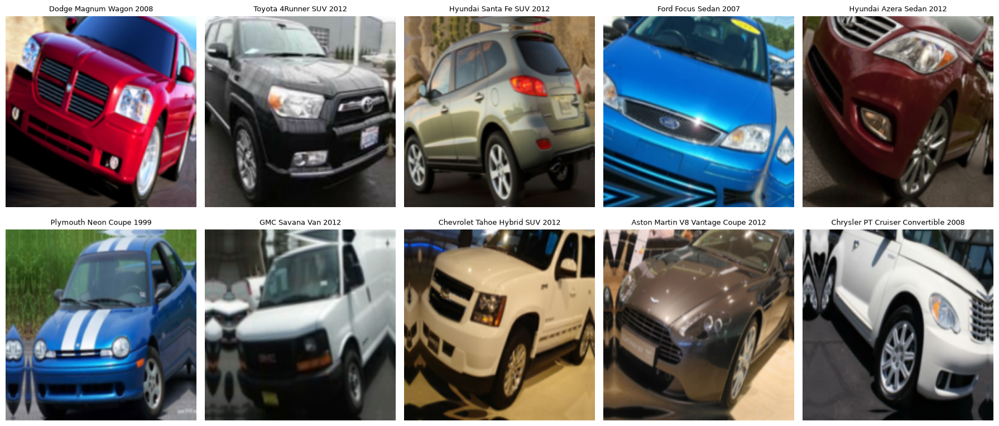

In [58]:
def make_data_augmentation():
    # CHANGED: graph-native layers replace legacy ImageDataGenerator.
    return tf.keras.Sequential(
        [
            tf.keras.layers.RandomFlip(
                "horizontal",
                seed=SEED,
            ),
            tf.keras.layers.RandomRotation(
                factor=20 / 360,
                seed=SEED,
            ),
            tf.keras.layers.RandomTranslation(
                height_factor=0.10,
                width_factor=0.10,
                seed=SEED,
            ),
            tf.keras.layers.RandomZoom(
                height_factor=0.10,
                width_factor=0.10,
                seed=SEED,
            ),
        ],
        name="data_augmentation",
    )


augmentation_preview = (
    make_data_augmentation()
)

augmented_images = (
    augmentation_preview(
        sample_images[:10],
        training=True,
    )
)

show_cropped_batch(
    augmented_images,
    sample_labels[:10],
    num=10,
    filename="augmented_samples.png",
)

# 3. Model development

## 3.1 Basic CNN baseline

The baseline remains close to the original assignment:

- Conv2D 32 → MaxPool
- Conv2D 64 → MaxPool
- Conv2D 128 → MaxPool
- Flatten
- Dense 512
- Dropout 0.5
- 196-way softmax

Its purpose is to demonstrate what happens when the project learns visual features from scratch rather than starting from an ImageNet representation.

**CHANGED:** augmentation and 0–1 scaling are embedded in the saved model.

In [60]:
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization,
)
from tensorflow.keras.metrics import (
    CategoricalAccuracy,
    TopKCategoricalAccuracy,
)
from tensorflow.keras.optimizers import Adam


def classification_metrics():
    # ADDED: top-3 accuracy mirrors the future Django UI.
    return [
        CategoricalAccuracy(
            name="accuracy"
        ),
        TopKCategoricalAccuracy(
            k=3,
            name="top3_accuracy",
        ),
    ]


def build_basic_cnn():
    inputs = Input(
        shape=(
            *IMAGE_SIZE,
            3,
        ),
        name="image",
    )

    # CHANGED: augmentation lives inside the model and is training-only.
    x = make_data_augmentation()(
        inputs
    )

    # EXISTING CONCEPT: custom CNN uses 0–1 scaled pixels.
    x = Rescaling(
        1.0 / 255.0,
        name="cnn_rescaling",
    )(x)

    x = Conv2D(
        32,
        (3, 3),
        activation="relu",
    )(x)
    x = MaxPooling2D(
        (2, 2)
    )(x)

    x = Conv2D(
        64,
        (3, 3),
        activation="relu",
    )(x)
    x = MaxPooling2D(
        (2, 2)
    )(x)

    x = Conv2D(
        128,
        (3, 3),
        activation="relu",
    )(x)
    x = MaxPooling2D(
        (2, 2)
    )(x)

    x = Flatten()(x)
    x = Dense(
        512,
        activation="relu",
    )(x)
    x = Dropout(
        0.50
    )(x)

    outputs = Dense(
        NUM_CLASSES,
        activation="softmax",
        name="predictions",
    )(x)

    model = Model(
        inputs,
        outputs,
        name="basic_cnn",
    )

    model.compile(
        optimizer=Adam(
            learning_rate=1e-3
        ),
        loss="categorical_crossentropy",
        metrics=classification_metrics(),
    )

    return model

## 3.2 Callbacks and training charts

The original project used:

- `EarlyStopping`
- `ReduceLROnPlateau`

Those are retained.

**ADDED:** `ModelCheckpoint` saves the best weights by validation loss. Fresh callback objects are created for every training stage so callback state cannot leak between stage 1 and fine-tuning.

In [61]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
)


def make_callbacks(
    weights_path,
):
    # EXISTING CONCEPT: stop after a validation-loss plateau.
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    )

    # EXISTING CONCEPT: reduce learning rate when validation loss stalls.
    lr_scheduler = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.1,
        patience=3,
        min_lr=1e-7,
        verbose=1,
    )

    # ADDED: persist the best weights for this training stage.
    checkpoint = ModelCheckpoint(
        filepath=str(
            weights_path
        ),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1,
    )

    return [
        early_stopping,
        lr_scheduler,
        checkpoint,
    ]


def plot_training_history(
    history,
    title,
    filename,
):
    history_df = pd.DataFrame(
        history.history
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5),
    )

    axes[0].plot(
        history_df["accuracy"],
        label="Train",
    )
    axes[0].plot(
        history_df["val_accuracy"],
        label="Validation",
    )
    axes[0].set_title(
        f"{title} — accuracy"
    )
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(
        history_df["top3_accuracy"],
        label="Train",
    )
    axes[1].plot(
        history_df["val_top3_accuracy"],
        label="Validation",
    )
    axes[1].set_title(
        f"{title} — top-3 accuracy"
    )
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel(
        "Top-3 accuracy"
    )
    axes[1].legend()

    axes[2].plot(
        history_df["loss"],
        label="Train",
    )
    axes[2].plot(
        history_df["val_loss"],
        label="Validation",
    )
    axes[2].set_title(
        f"{title} — loss"
    )
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Loss")
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / filename,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

Model: "basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_rescaling (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 196)            │       100,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,496,644 (169.74 MB)

 Trainable params: 44,496,644 (169.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


/home/sergiu/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791330827.958531   14488 cuda_dnn.cc:461] Loaded cuDNN version 92700


342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.0079 - loss: 5.2342 - top3_accuracy: 0.0243
Epoch 1: val_loss improved from None to 5.16571, saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5

Epoch 1: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 53s 51ms/step - accuracy: 0.0079 - loss: 5.2342 - top3_accuracy: 0.0243 - val_accuracy: 0.0110 - val_loss: 5.1657 - val_top3_accuracy: 0.0316 - learning_rate: 0.0010
Epoch 2/20
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.0150 - loss: 5.1450 - top3_accuracy: 0.0363
Epoch 2: val_loss improved from 5.16571 to 5.10121, saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5

Epoch 2: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.0150 - loss: 5.1449 - top3_accuracy: 0.0363 - val_

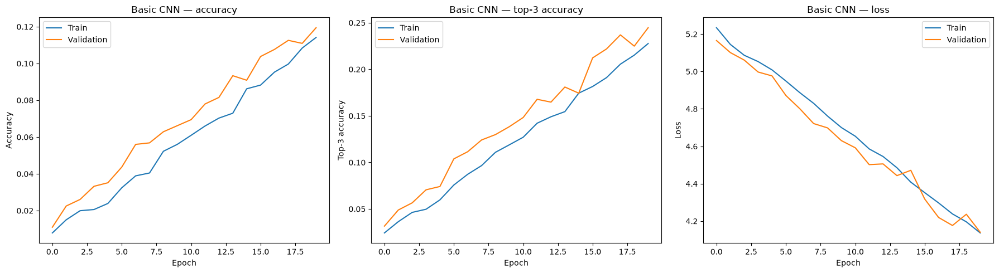

In [ ]:
baseline_history = None
baseline_metrics = None

if TRAIN_BASELINE:
    # ADDED: clean up any experimental graphs before the real baseline run.
    tf.keras.backend.clear_session()
    gc.collect()

    baseline_model = (
        build_basic_cnn()
    )

    baseline_model.summary()

    baseline_weights_path = (
        ARTIFACT_DIR
        / "baseline_best.weights.h5"
    )

    # CHANGED: no manual steps_per_epoch; every batch is consumed.
    baseline_history = baseline_model.fit(
    train_ds,
    epochs=BASELINE_EPOCHS,
    validation_data=val_ds,

    # ADDED: train_ds already performs .shuffle(...), so Keras does not need
    # to try applying its own shuffle setting to a tf.data.Dataset.
    shuffle=False,

    callbacks=make_callbacks(
        baseline_weights_path
    ),
)

    # ADDED: explicitly restore the minimum-val-loss checkpoint.
    baseline_model.load_weights(
        baseline_weights_path
    )

    baseline_metrics = (
        baseline_model.evaluate(
            test_ds,
            return_dict=True,
            verbose=1,
        )
    )

    baseline_model.save(
        ARTIFACT_DIR
        / "baseline_cnn.keras"
    )

    print(
        "Baseline test metrics:",
        baseline_metrics,
    )

    plot_training_history(
        baseline_history,
        title="Basic CNN",
        filename=(
            "baseline_training_history.png"
        ),
    )
else:
    print(
        "Baseline training skipped "
        "because TRAIN_BASELINE=False."
    )

In [64]:
# ADDED: continue the baseline because epoch 20 was still improving.
# The model currently holds the best epoch-20 weights.

baseline_continue_weights_path = (
    ARTIFACT_DIR
    / "baseline_best.weights.h5"
)

# ADDED: use fresh callbacks so patience counters start cleanly.
baseline_continue_history = baseline_model.fit(
    train_ds,

    # CHANGED: continue from epoch 20 up to a maximum of 50 total epochs.
    initial_epoch=20,
    epochs=50,

    validation_data=val_ds,

    # ADDED: the tf.data pipeline already shuffles the training dataset.
    shuffle=False,

    callbacks=make_callbacks(
        baseline_continue_weights_path
    ),
)

Epoch 21/50
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1240 - loss: 4.0738 - top3_accuracy: 0.2416
Epoch 21: val_loss improved from None to 4.05210, saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5

Epoch 21: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 17s 49ms/step - accuracy: 0.1239 - loss: 4.0745 - top3_accuracy: 0.2415 - val_accuracy: 0.1381 - val_loss: 4.0521 - val_top3_accuracy: 0.2540 - learning_rate: 0.0010
Epoch 22/50
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1289 - loss: 4.0301 - top3_accuracy: 0.2516
Epoch 22: val_loss improved from 4.05210 to 3.99852, saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5

Epoch 22: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/baseline_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.1291 - loss: 4.0294 - top3_accura

In [65]:
# ADDED: restore whichever continued epoch achieved the lowest validation loss.
baseline_model.load_weights(
    ARTIFACT_DIR
    / "baseline_best.weights.h5"
)

# CHANGED: evaluate the true final baseline after allowing EarlyStopping to work.
baseline_metrics = baseline_model.evaluate(
    test_ds,
    return_dict=True,
)

print(
    "Final baseline test metrics:",
    baseline_metrics,
)

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.3064 - loss: 3.1299 - top3_accuracy: 0.5053
Final baseline test metrics: {'accuracy': 0.30636194348335266, 'loss': 3.129916191101074, 'top3_accuracy': 0.5052501559257507}


## 3.3 MobileNetV2 transfer learning

The original project used MobileNetV2 with ImageNet weights and achieved a large improvement over the custom CNN.

This notebook retains MobileNetV2 but replaces the original large custom head.

### Updated head

1. MobileNetV2 backbone
2. GlobalAveragePooling2D
3. Dropout
4. 196-way softmax

The original head used multiple large 1×1 convolutions followed by `Flatten`. The new head is substantially lighter and better suited to deployment.

### Preprocessing

MobileNetV2 expects values near **[-1, 1]**.

`Rescaling(1 / 127.5, offset=-1)` is embedded directly in the model so Django does not need to duplicate the scaling logic.

In [67]:
from tensorflow.keras.applications import (
    MobileNetV2,
)


def build_mobilenet_model():
    inputs = Input(
        shape=(
            *IMAGE_SIZE,
            3,
        ),
        name="image",
    )

    # CHANGED: augmentation is embedded and automatically disabled at inference.
    x = make_data_augmentation()(
        inputs
    )

    # CHANGED: embed MobileNetV2-compatible [-1, 1] scaling.
    x = Rescaling(
        scale=1.0 / 127.5,
        offset=-1.0,
        name=(
            "mobilenet_preprocessing"
        ),
    )(x)

    # EXISTING CONCEPT: ImageNet transfer learning.
    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(
            *IMAGE_SIZE,
            3,
        ),
    )

    # CHANGED: stage 1 trains only the new classifier head.
    base_model.trainable = False

    # ADDED: keep BatchNorm inference behavior stable.
    x = base_model(
        x,
        training=False,
    )

    # CHANGED: lightweight head instead of Conv2D stack + Flatten.
    x = GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = Dropout(
        0.30,
        name="classifier_dropout",
    )(x)

    outputs = Dense(
        NUM_CLASSES,
        activation="softmax",
        name="predictions",
    )(x)

    model = Model(
        inputs,
        outputs,
        name=(
            "stanford_cars_mobilenetv2"
        ),
    )

    model.compile(
        optimizer=Adam(
            learning_rate=1e-3
        ),
        loss="categorical_crossentropy",
        metrics=classification_metrics(),
    )

    return model, base_model

## 3.4 Stage 1 — train the new classifier head

MobileNetV2 remains frozen initially.

This lets the new 196-class head learn the Stanford Cars task before any pretrained features are modified.

In [68]:
# ADDED: release baseline GPU memory before constructing MobileNetV2.
if "baseline_model" in globals():
    del baseline_model

tf.keras.backend.clear_session()
gc.collect()

mobilenet_model, base_model = (
    build_mobilenet_model()
)

mobilenet_model.summary()

stage1_weights_path = (
    ARTIFACT_DIR
    / "mobilenet_stage1_best.weights.h5"
)

history_head = mobilenet_model.fit(
    train_ds,
    epochs=HEAD_EPOCHS,
    validation_data=val_ds,
    callbacks=make_callbacks(
        stage1_weights_path
    ),
)

# ADDED: fine-tuning begins from the best stage-1 validation checkpoint.
mobilenet_model.load_weights(
    stage1_weights_path
)

stage1_best_val_loss = min(
    history_head.history[
        "val_loss"
    ]
)

print(
    "Best stage-1 validation loss:",
    f"{stage1_best_val_loss:.6f}",
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "stanford_cars_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 196)            │       251,076 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,509,060 (9.57 MB)

 Trainable params: 251,076 (980.77 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1160 - loss: 4.3269 - top3_accuracy: 0.2283
Epoch 1: val_loss improved from None to 3.22561, saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5

Epoch 1: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 28s 45ms/step - accuracy: 0.1162 - loss: 4.3263 - top3_accuracy: 0.2284 - val_accuracy: 0.2856 - val_loss: 3.2256 - val_top3_accuracy: 0.4843 - learning_rate: 0.0010
Epoch 2/15
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3098 - loss: 2.9735 - top3_accuracy: 0.5062
Epoch 2: val_loss improved from 3.22561 to 2.70085, saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5

Epoch 2: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.3097 - 

In [69]:
# ADDED: continue training the frozen MobileNetV2 head because
# validation loss was still improving at epoch 15.

stage1_continue_weights_path = (
    ARTIFACT_DIR
    / "mobilenet_stage1_best.weights.h5"
)

history_head_continue = mobilenet_model.fit(
    train_ds,

    # CHANGED: continue from epoch 15 rather than restarting.
    initial_epoch=15,
    epochs=45,

    validation_data=val_ds,

    # ADDED: tf.data already handles shuffling internally.
    shuffle=False,

    # ADDED: fresh callbacks reset EarlyStopping/LR scheduler state.
    callbacks=make_callbacks(
        stage1_continue_weights_path
    ),
)

Epoch 16/45
340/342 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6863 - loss: 1.1521 - top3_accuracy: 0.8649
Epoch 16: val_loss improved from None to 1.70229, saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5

Epoch 16: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 15s 43ms/step - accuracy: 0.6862 - loss: 1.1527 - top3_accuracy: 0.8646 - val_accuracy: 0.5500 - val_loss: 1.7023 - val_top3_accuracy: 0.7683 - learning_rate: 0.0010
Epoch 17/45
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6914 - loss: 1.1422 - top3_accuracy: 0.8641
Epoch 17: val_loss improved from 1.70229 to 1.69112, saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5

Epoch 17: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage1_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.6

In [71]:
# ADDED: restore the best frozen-backbone checkpoint before fine-tuning.
mobilenet_model.load_weights(
    ARTIFACT_DIR
    / "mobilenet_stage1_best.weights.h5"
)

# CHANGED: calculate best validation loss across both stage-1 runs.
stage1_best_val_loss = min(
    min(history_head.history["val_loss"]),
    min(history_head_continue.history["val_loss"]),
)

print(
    "Best stage-1 validation loss:",
    stage1_best_val_loss
)

Best stage-1 validation loss: 1.517816424369812


## 3.5 Stage 2 — fine-tune the final MobileNetV2 layers

Only the final `FINE_TUNE_LAYERS` are allowed to adapt.

Safeguards:

- BatchNormalization layers stay frozen.
- The model is recompiled after changing `trainable`.
- Learning rate falls from `1e-3` to `1e-5`.
- A fresh callback set is used.

In [72]:
history_fine_tune = None
stage2_best_val_loss = np.inf

if RUN_FINE_TUNING:
    # CHANGED: unlock the backbone before selectively freezing most layers.
    base_model.trainable = True

    for layer in base_model.layers[
        :-FINE_TUNE_LAYERS
    ]:
        layer.trainable = False

    # ADDED: keep BatchNormalization statistics frozen during fine-tuning.
    for layer in base_model.layers:
        if isinstance(
            layer,
            BatchNormalization,
        ):
            layer.trainable = False

    trainable_backbone_layers = sum(
        int(layer.trainable)
        for layer in base_model.layers
    )

    print(
        "Trainable MobileNetV2 "
        "backbone layers:",
        f"{trainable_backbone_layers}/"
        f"{len(base_model.layers)}",
    )

    # IMPORTANT / CHANGED: compile again after modifying trainable flags.
    mobilenet_model.compile(
        optimizer=Adam(
            learning_rate=1e-5
        ),
        loss="categorical_crossentropy",
        metrics=classification_metrics(),
    )

    stage2_weights_path = (
        ARTIFACT_DIR
        / "mobilenet_stage2_best.weights.h5"
    )

    history_fine_tune = (
        mobilenet_model.fit(
            train_ds,
            epochs=FINE_TUNE_EPOCHS,
            validation_data=val_ds,
            callbacks=make_callbacks(
                stage2_weights_path
            ),
        )
    )

    stage2_best_val_loss = min(
        history_fine_tune.history[
            "val_loss"
        ]
    )

    print(
        "Best stage-2 validation loss:",
        f"{stage2_best_val_loss:.6f}",
    )
else:
    print(
        "Fine-tuning skipped because "
        "RUN_FINE_TUNING=False."
    )

Trainable MobileNetV2 backbone layers: 13/154
Epoch 1/20
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7920 - loss: 0.7316 - top3_accuracy: 0.9294
Epoch 1: val_loss improved from None to 1.46777, saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage2_best.weights.h5

Epoch 1: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage2_best.weights.h5
342/342 ━━━━━━━━━━━━━━━━━━━━ 27s 52ms/step - accuracy: 0.7920 - loss: 0.7316 - top3_accuracy: 0.9294 - val_accuracy: 0.6192 - val_loss: 1.4678 - val_top3_accuracy: 0.8100 - learning_rate: 1.0000e-05
Epoch 2/20
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8111 - loss: 0.6620 - top3_accuracy: 0.9386
Epoch 2: val_loss improved from 1.46777 to 1.44453, saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage2_best.weights.h5

Epoch 2: finished saving model to /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage2_best.weights.h5
342/342 ━━━━━━

## 3.6 Select the best transfer-learning stage

Fine-tuning is kept only if it improves validation loss.

The selected model is exported as:

`artifacts/car_classifier.keras`

This is the model intended for the Django application.

In [89]:
# %% Final model selection

# ADDED: rebuild the true best Stage-1 validation loss from both frozen-backbone runs.
stage1_val_losses = list(
    history_head.history["val_loss"]
)

if "history_head_continue" in globals():
    stage1_val_losses += list(
        history_head_continue.history["val_loss"]
    )

stage1_best_val_loss = min(
    stage1_val_losses
)


# ADDED: get the best Stage-2 validation loss from the completed fine-tuning run.
stage2_best_val_loss = min(
    history_fine_tune.history["val_loss"]
)


# CHANGED: select the model using validation loss only.
if (
    RUN_FINE_TUNING
    and stage2_best_val_loss < stage1_best_val_loss
):
    selected_stage = "fine_tuned"

    # ADDED: Stage 2 won, so restore its best checkpoint.
    final_weights_path = (
        ARTIFACT_DIR
        / "mobilenet_stage2_best.weights.h5"
    )

else:
    selected_stage = "frozen_backbone"

    # ADDED: fall back to Stage 1 if fine-tuning was worse.
    final_weights_path = (
        ARTIFACT_DIR
        / "mobilenet_stage1_best.weights.h5"
    )


# ADDED: load the winning weights explicitly.
mobilenet_model.load_weights(
    final_weights_path
)


print(
    f"Stage 1 best val loss: "
    f"{stage1_best_val_loss:.6f}"
)

print(
    f"Stage 2 best val loss: "
    f"{stage2_best_val_loss:.6f}"
)

print(
    "Selected stage:",
    selected_stage
)

print(
    "Selected weights:",
    final_weights_path
)


# ADDED: save the complete deployment model.
FINAL_MODEL_PATH = (
    ARTIFACT_DIR
    / "car_classifier.keras"
)

mobilenet_model.save(
    FINAL_MODEL_PATH
)

print(
    "Saved final model:",
    FINAL_MODEL_PATH
)

Stage 1 best val loss: 1.517816
Stage 2 best val loss: 1.188274
Selected stage: fine_tuned
Selected weights: /home/sergiu/projects/stanford-cars/artifacts/mobilenet_stage2_best.weights.h5
Saved final model: /home/sergiu/projects/stanford-cars/artifacts/car_classifier.keras


In [90]:
# %% Verify selected MobileNetV2 checkpoint

# ADDED: verify the loaded checkpoint before touching the test set.
selected_val_metrics = mobilenet_model.evaluate(
    val_ds,
    return_dict=True,
    verbose=1,
)

print(
    "\nSelected model validation metrics:"
)

for name, value in selected_val_metrics.items():
    print(
        f"{name}: {value:.4f}"
    )

114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.6914 - loss: 1.1883 - top3_accuracy: 0.8655

Selected model validation metrics:
accuracy: 0.6914
loss: 1.1883
top3_accuracy: 0.8655


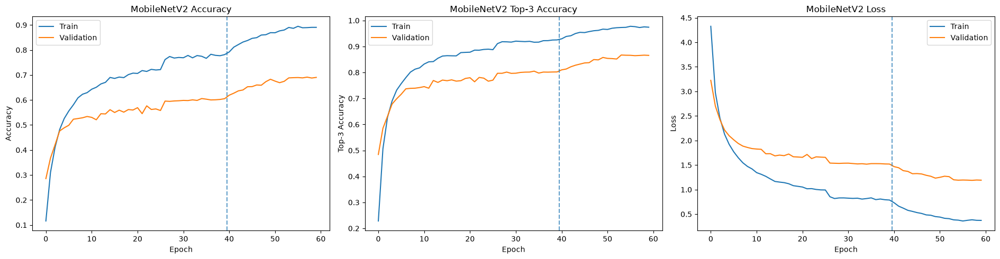

In [91]:
# %% Plot complete MobileNetV2 training history

# ADDED: combine Stage 1 initial training,
# Stage 1 continuation and Stage 2 fine-tuning.
def combined_history_values(metric):
    values = list(
        history_head.history.get(
            metric,
            []
        )
    )

    # ADDED: include the extra frozen-backbone epochs.
    if "history_head_continue" in globals():
        values += list(
            history_head_continue.history.get(
                metric,
                []
            )
        )

    # ADDED: append fine-tuning after Stage 1.
    if history_fine_tune is not None:
        values += list(
            history_fine_tune.history.get(
                metric,
                []
            )
        )

    return values


# ADDED: collect complete experiment histories.
combined_accuracy = combined_history_values(
    "accuracy"
)

combined_val_accuracy = combined_history_values(
    "val_accuracy"
)

combined_top3 = combined_history_values(
    "top3_accuracy"
)

combined_val_top3 = combined_history_values(
    "val_top3_accuracy"
)

combined_loss = combined_history_values(
    "loss"
)

combined_val_loss = combined_history_values(
    "val_loss"
)


# ADDED: calculate where fine-tuning began.
fine_tune_start = len(
    history_head.history["loss"]
)

if "history_head_continue" in globals():
    fine_tune_start += len(
        history_head_continue.history["loss"]
    )


# ADDED: create one figure with the three important training metrics.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5)
)


# Accuracy
axes[0].plot(
    combined_accuracy,
    label="Train"
)

axes[0].plot(
    combined_val_accuracy,
    label="Validation"
)

axes[0].set_title(
    "MobileNetV2 Accuracy"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Accuracy"
)

axes[0].legend()


# Top-3 accuracy
axes[1].plot(
    combined_top3,
    label="Train"
)

axes[1].plot(
    combined_val_top3,
    label="Validation"
)

axes[1].set_title(
    "MobileNetV2 Top-3 Accuracy"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Top-3 Accuracy"
)

axes[1].legend()


# Loss
axes[2].plot(
    combined_loss,
    label="Train"
)

axes[2].plot(
    combined_val_loss,
    label="Validation"
)

axes[2].set_title(
    "MobileNetV2 Loss"
)

axes[2].set_xlabel(
    "Epoch"
)

axes[2].set_ylabel(
    "Loss"
)

axes[2].legend()


# ADDED: mark the transition from frozen transfer learning
# to fine-tuning of pretrained MobileNetV2 layers.
for axis in axes:
    axis.axvline(
        fine_tune_start - 0.5,
        linestyle="--",
        alpha=0.7,
        label="Fine-tuning begins"
    )


plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "mobilenet_training_history.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# 4. Results and discussion

## 4.1 Held-out test performance

The held-out test split has not been used for early stopping or stage selection.

The final evaluation includes:

- loss,
- top-1 accuracy,
- top-3 accuracy,
- macro precision,
- macro recall,
- macro F1,
- weighted metrics,
- per-class metrics.

The complete 196-class report is saved to `classification_report.csv`.

In [93]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# ADDED: evaluate the selected final model once on the held-out set.
final_test_metrics = (
    mobilenet_model.evaluate(
        test_ds,
        return_dict=True,
        verbose=1,
    )
)

print(
    "Final test metrics:"
)

for (
    metric_name,
    metric_value,
) in final_test_metrics.items():
    print(
        f"{metric_name}: "
        f"{metric_value:.6f}"
    )

# ADDED: test_ds is not shuffled, so output order matches test_data.
test_probabilities = (
    mobilenet_model.predict(
        test_ds,
        verbose=1,
    )
)

y_true = (
    test_data[
        "label_zero"
    ]
    .to_numpy()
)

y_pred = np.argmax(
    test_probabilities,
    axis=1,
)

assert len(y_true) == len(y_pred)

report_dict = (
    classification_report(
        y_true,
        y_pred,
        labels=np.arange(
            NUM_CLASSES
        ),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
)

classification_report_df = (
    pd.DataFrame(
        report_dict
    ).T
)

classification_report_df.to_csv(
    ARTIFACT_DIR
    / "classification_report.csv"
)

display(
    classification_report_df.loc[
        [
            "macro avg",
            "weighted avg",
        ]
    ]
)

macro_precision = float(
    report_dict[
        "macro avg"
    ]["precision"]
)
macro_recall = float(
    report_dict[
        "macro avg"
    ]["recall"]
)
macro_f1 = float(
    report_dict[
        "macro avg"
    ]["f1-score"]
)

print(
    f"Macro precision: "
    f"{macro_precision:.4f}"
)
print(
    f"Macro recall:    "
    f"{macro_recall:.4f}"
)
print(
    f"Macro F1:        "
    f"{macro_f1:.4f}"
)

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.7159 - loss: 1.1891 - top3_accuracy: 0.8567
Final test metrics:
accuracy: 0.715874
loss: 1.189100
top3_accuracy: 0.856702
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step


,precision,recall,f1-score,support
macro avg,0.75548,0.714784,0.712868,1619.0
weighted avg,0.75375,0.715874,0.712583,1619.0


Macro precision: 0.7555
Macro recall:    0.7148
Macro F1:        0.7129


## 4.2 Strongest and weakest classes

Overall accuracy does not show which fine-grained vehicles remain difficult.

The next chart compares the 15 lowest and 15 highest class F1 scores.

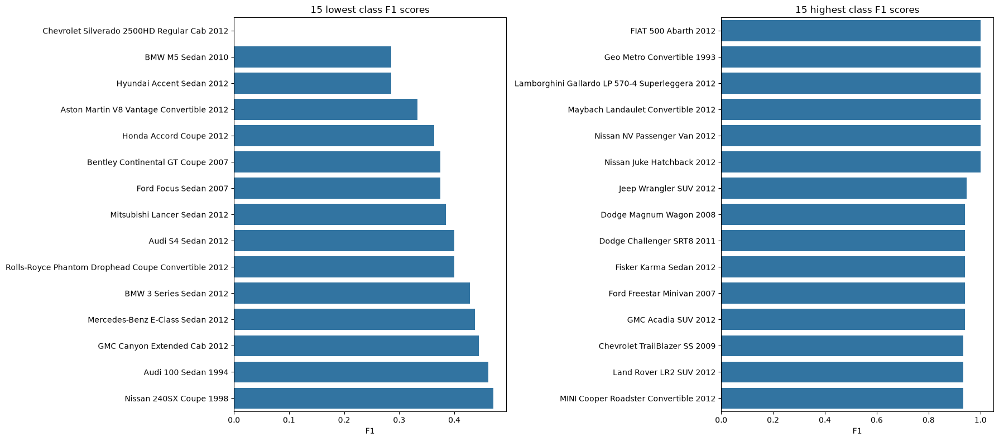

In [94]:
# ADDED: the first 196 rows correspond to the individual classes.
per_class_report = (
    classification_report_df
    .iloc[:NUM_CLASSES]
    .copy()
)

per_class_report[
    "f1-score"
] = pd.to_numeric(
    per_class_report[
        "f1-score"
    ]
)

lowest_f1 = (
    per_class_report
    .nsmallest(
        15,
        "f1-score",
    )
)

highest_f1 = (
    per_class_report
    .nlargest(
        15,
        "f1-score",
    )
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8),
)

sns.barplot(
    x=lowest_f1[
        "f1-score"
    ],
    y=lowest_f1.index,
    ax=axes[0],
)
axes[0].set_title(
    "15 lowest class F1 scores"
)
axes[0].set_xlabel("F1")
axes[0].set_ylabel("")

sns.barplot(
    x=highest_f1[
        "f1-score"
    ],
    y=highest_f1.index,
    ax=axes[1],
)
axes[1].set_title(
    "15 highest class F1 scores"
)
axes[1].set_xlabel("F1")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR
    / "class_f1_extremes.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 4.3 Most common confusion pairs

A full 196×196 confusion heatmap is hard to read.

Instead, the diagonal is removed and the 15 most frequent **actual → predicted** mistakes are ranked.

,actual,predicted,count,pair
0,Bentley Continental GT Coupe 2007,Bentley Continental GT Coupe 2012,4,Bentley Continental GT Coupe 2007 → Bentley Co...
1,Dodge Sprinter Cargo Van 2009,Mercedes-Benz Sprinter Van 2012,4,Dodge Sprinter Cargo Van 2009 → Mercedes-Benz ...
2,Chevrolet Silverado 2500HD Regular Cab 2012,Chevrolet Silverado 1500 Regular Cab 2012,4,Chevrolet Silverado 2500HD Regular Cab 2012 → ...
3,BMW 6 Series Convertible 2007,BMW M6 Convertible 2010,3,BMW 6 Series Convertible 2007 → BMW M6 Convert...
4,Bentley Continental GT Coupe 2012,Bentley Continental GT Coupe 2007,3,Bentley Continental GT Coupe 2012 → Bentley Co...
5,Suzuki SX4 Sedan 2012,Scion xD Hatchback 2012,3,Suzuki SX4 Sedan 2012 → Scion xD Hatchback 2012
6,Audi 100 Sedan 1994,Audi V8 Sedan 1994,3,Audi 100 Sedan 1994 → Audi V8 Sedan 1994
7,Hyundai Genesis Sedan 2012,Mercedes-Benz E-Class Sedan 2012,2,Hyundai Genesis Sedan 2012 → Mercedes-Benz E-C...
8,Eagle Talon Hatchback 1998,Nissan 240SX Coupe 1998,2,Eagle Talon Hatchback 1998 → Nissan 240SX Coup...
9,Aston Martin V8 Vantage Convertible 2012,Aston Martin V8 Vantage Coupe 2012,2,Aston Martin V8 Vantage Convertible 2012 → Ast...


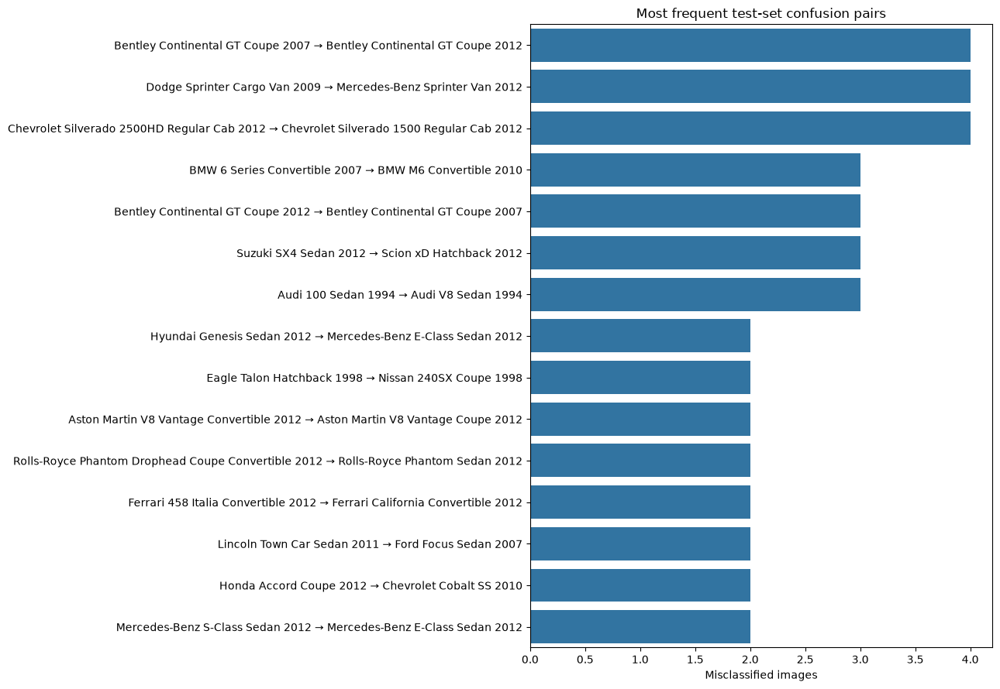

In [95]:
confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        NUM_CLASSES
    ),
)

# ADDED: remove correct predictions before ranking errors.
confusion_without_diagonal = (
    confusion.copy()
)

np.fill_diagonal(
    confusion_without_diagonal,
    0,
)

flat_indices = np.argsort(
    confusion_without_diagonal.ravel()
)[::-1]

top_confusions = []

for flat_index in flat_indices:
    (
        actual_index,
        predicted_index,
    ) = np.unravel_index(
        flat_index,
        confusion_without_diagonal.shape,
    )

    count = int(
        confusion_without_diagonal[
            actual_index,
            predicted_index,
        ]
    )

    if count == 0:
        break

    top_confusions.append(
        {
            "actual": (
                class_names[
                    actual_index
                ]
            ),
            "predicted": (
                class_names[
                    predicted_index
                ]
            ),
            "count": count,
            "pair": (
                f"{class_names[actual_index]}"
                f" → "
                f"{class_names[predicted_index]}"
            ),
        }
    )

    if len(top_confusions) == 15:
        break

top_confusions_df = pd.DataFrame(
    top_confusions
)

display(
    top_confusions_df
)

plt.figure(
    figsize=(13, 9)
)

sns.barplot(
    data=top_confusions_df,
    x="count",
    y="pair",
)

plt.title(
    "Most frequent test-set confusion pairs"
)
plt.xlabel(
    "Misclassified images"
)
plt.ylabel("")

save_and_show_figure(
    "top_confusion_pairs.png"
)

## 4.4 Example test predictions

The planned Django demo will show held-out cars and return the model's top three predictions.

This cell previews the same interaction using a fixed random sample rather than cherry-picking successful predictions.

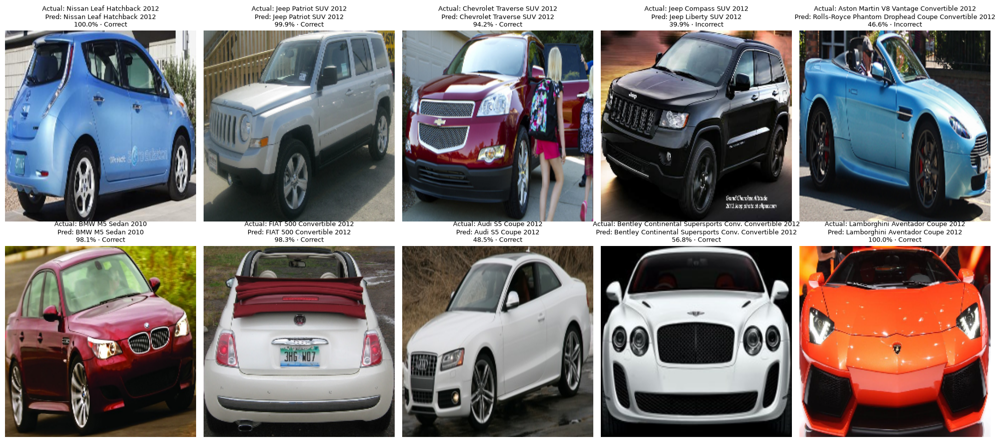

,image_id,actual,top_1,top_1_confidence,top_2,top_2_confidence,top_3,top_3_confidence,correct
0,test_03739.jpg,Nissan Leaf Hatchback 2012,Nissan Leaf Hatchback 2012,0.999997,Scion xD Hatchback 2012,6.152087e-07,Chevrolet Traverse SUV 2012,5.434746e-07,True
1,test_06045.jpg,Jeep Patriot SUV 2012,Jeep Patriot SUV 2012,0.998809,Jeep Liberty SUV 2012,1.080889e-03,Jeep Grand Cherokee SUV 2012,4.676029e-05,True
2,train_00692.jpg,Chevrolet Traverse SUV 2012,Chevrolet Traverse SUV 2012,0.941823,Suzuki Kizashi Sedan 2012,2.792579e-02,Chevrolet Impala Sedan 2007,9.427818e-03,True
3,test_07373.jpg,Jeep Compass SUV 2012,Jeep Liberty SUV 2012,0.399002,Jeep Grand Cherokee SUV 2012,3.716657e-01,GMC Yukon Hybrid SUV 2012,1.834631e-01,False
4,train_02377.jpg,Aston Martin V8 Vantage Convertible 2012,Rolls-Royce Phantom Drophead Coupe Convertible...,0.465863,Audi RS 4 Convertible 2008,1.263378e-01,Audi S5 Convertible 2012,7.790256e-02,False
5,test_04915.jpg,BMW M5 Sedan 2010,BMW M5 Sedan 2010,0.981293,BMW 1 Series Coupe 2012,6.658664e-03,BMW 3 Series Sedan 2012,5.247102e-03,True
6,test_01119.jpg,FIAT 500 Convertible 2012,FIAT 500 Convertible 2012,0.983205,Volkswagen Beetle Hatchback 2012,4.932776e-03,Buick Regal GS 2012,3.748992e-03,True
7,train_04676.jpg,Audi S5 Coupe 2012,Audi S5 Coupe 2012,0.484916,Audi A5 Coupe 2012,4.246251e-01,Audi S4 Sedan 2007,3.909215e-02,True
8,train_02234.jpg,Bentley Continental Supersports Conv. Converti...,Bentley Continental Supersports Conv. Converti...,0.568128,Bentley Continental GT Coupe 2012,3.319140e-01,Bentley Continental Flying Spur Sedan 2007,3.397263e-02,True
9,test_06606.jpg,Lamborghini Aventador Coupe 2012,Lamborghini Aventador Coupe 2012,0.999957,Hyundai Veloster Hatchback 2012,2.536322e-05,Jaguar XK XKR 2012,5.955721e-06,True


In [96]:
def load_cropped_rgb_for_plot(
    row,
):
    image = read_rgb_image(
        PROJECT_ROOT
        / row["relative_path"]
    )

    x1 = int(row["x1"])
    y1 = int(row["y1"])
    x2 = int(row["x2"])
    y2 = int(row["y2"])

    crop = image[
        y1:y2,
        x1:x2,
    ]

    # EXISTING CONCEPT: use the same 224×224 crop geometry.
    crop = cv2.resize(
        crop,
        IMAGE_SIZE,
    )

    return crop


rng = np.random.default_rng(
    SEED
)

prediction_indices = (
    rng.choice(
        len(test_data),
        size=10,
        replace=False,
    )
)

prediction_rows = []

plt.figure(
    figsize=(20, 9)
)

for (
    plot_position,
    test_index,
) in enumerate(
    prediction_indices
):
    row = test_data.iloc[
        test_index
    ]

    probabilities = (
        test_probabilities[
            test_index
        ]
    )

    top3_indices = np.argsort(
        probabilities
    )[-3:][::-1]

    predicted_index = int(
        top3_indices[0]
    )

    actual_index = int(
        row["label_zero"]
    )

    ax = plt.subplot(
        2,
        5,
        plot_position + 1,
    )

    ax.imshow(
        load_cropped_rgb_for_plot(
            row
        )
    )

    is_correct = (
        predicted_index
        == actual_index
    )

    ax.set_title(
        (
            f"Actual: "
            f"{class_names[actual_index]}\n"
            f"Pred: "
            f"{class_names[predicted_index]}\n"
            f"{probabilities[predicted_index]:.1%}"
            f" · "
            f"{'Correct' if is_correct else 'Incorrect'}"
        ),
        fontsize=9,
    )

    ax.axis("off")

    prediction_rows.append(
        {
            "image_id": (
                row["image_id"]
            ),
            "actual": (
                class_names[
                    actual_index
                ]
            ),
            "top_1": (
                class_names[
                    top3_indices[0]
                ]
            ),
            "top_1_confidence": float(
                probabilities[
                    top3_indices[0]
                ]
            ),
            "top_2": (
                class_names[
                    top3_indices[1]
                ]
            ),
            "top_2_confidence": float(
                probabilities[
                    top3_indices[1]
                ]
            ),
            "top_3": (
                class_names[
                    top3_indices[2]
                ]
            ),
            "top_3_confidence": float(
                probabilities[
                    top3_indices[2]
                ]
            ),
            "correct": bool(
                is_correct
            ),
        }
    )

plt.tight_layout()
plt.savefig(
    FIGURE_DIR
    / "sample_test_predictions.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

prediction_examples_df = (
    pd.DataFrame(
        prediction_rows
    )
)

display(
    prediction_examples_df
)

## 4.5 Historical vs retrained models

The original technical report recorded:

| Model | Test accuracy |
|---|---:|
| Basic CNN | 30.82% |
| MobileNetV2 | 72.45% |

These are **historical project results**, not the new results.

The next chart places the freshly measured models beside those historical values.

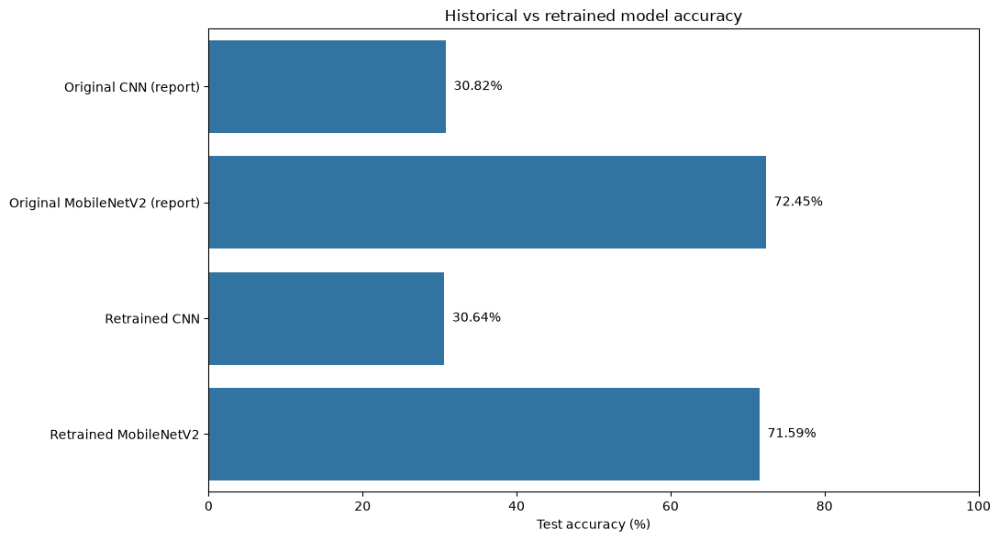

,model,accuracy_percent
0,Original CNN (report),30.820000
1,Original MobileNetV2 (report),72.450000
2,Retrained CNN,30.636194
3,Retrained MobileNetV2,71.587402


In [97]:
comparison_rows = [
    {
        "model": (
            "Original CNN "
            "(report)"
        ),
        "accuracy_percent": 30.82,
    },
    {
        "model": (
            "Original MobileNetV2 "
            "(report)"
        ),
        "accuracy_percent": 72.45,
    },
]

if baseline_metrics is not None:
    comparison_rows.append(
        {
            "model": (
                "Retrained CNN"
            ),
            "accuracy_percent": (
                float(
                    baseline_metrics[
                        "accuracy"
                    ]
                )
                * 100
            ),
        }
    )

comparison_rows.append(
    {
        "model": (
            "Retrained MobileNetV2"
        ),
        "accuracy_percent": (
            float(
                final_test_metrics[
                    "accuracy"
                ]
            )
            * 100
        ),
    }
)

model_comparison_df = (
    pd.DataFrame(
        comparison_rows
    )
)

plt.figure(
    figsize=(11, 6)
)

sns.barplot(
    data=model_comparison_df,
    x="accuracy_percent",
    y="model",
)

plt.title(
    "Historical vs retrained model accuracy"
)
plt.xlabel(
    "Test accuracy (%)"
)
plt.ylabel("")
plt.xlim(0, 100)

for (
    index,
    row,
) in model_comparison_df.iterrows():
    plt.text(
        row["accuracy_percent"] + 1,
        index,
        (
            f'{row["accuracy_percent"]:.2f}%'
        ),
        va="center",
    )

save_and_show_figure(
    "historical_vs_retrained_accuracy.png"
)

display(
    model_comparison_df
)

# 5. Export deployment artifacts

Training and Django have separate responsibilities.

### Notebook
- prepares data,
- trains models,
- evaluates,
- exports immutable artifacts.

### Django
- loads the final model once,
- chooses held-out demo images,
- applies the known bounding-box crop,
- returns top-3 predictions.

Expected artifact structure:

```text
artifacts/
├── car_classifier.keras
├── class_names.json
├── metrics.json
├── training_history.json
├── classification_report.csv
├── train_split.csv
├── val_split.csv
├── test_split.csv
├── demo_images.json
└── figures/
```

The demo pool is sampled only from the held-out test split and is **not** filtered based on prediction correctness.

In [98]:
# ADDED: exact class-index mapping for Django.
with open(
    ARTIFACT_DIR
    / "class_names.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        class_names,
        file,
        indent=2,
    )


def history_to_json(
    history,
):
    # ADDED: make Keras History JSON-serializable.
    if history is None:
        return None

    return {
        key: [
            float(value)
            for value in values
        ]
        for key, values
        in history.history.items()
    }


# ADDED: preserve the continuation separately for reproducibility.
training_history_export = {
    "baseline": history_to_json(
        baseline_history
    ),
    "mobilenet_stage1_initial": history_to_json(
        history_head
    ),
    "mobilenet_stage1_continue": history_to_json(
        history_head_continue
        if "history_head_continue" in globals()
        else None
    ),
    "mobilenet_fine_tune": history_to_json(
        history_fine_tune
    ),
}

with open(
    ARTIFACT_DIR
    / "training_history.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_history_export,
        file,
        indent=2,
    )


# ADDED: metrics used by the portfolio case study and future API.
metrics_export = {
    "selected_stage": (
        selected_stage
    ),
    "test_loss": float(
        final_test_metrics[
            "loss"
        ]
    ),
    "test_accuracy": float(
        final_test_metrics[
            "accuracy"
        ]
    ),
    "test_top3_accuracy": float(
        final_test_metrics[
            "top3_accuracy"
        ]
    ),
    "macro_precision": (
        macro_precision
    ),
    "macro_recall": (
        macro_recall
    ),
    "macro_f1": (
        macro_f1
    ),
    "historical_original_cnn_accuracy": (
        0.3082
    ),
    "historical_original_mobilenet_accuracy": (
        0.7245
    ),
}

if baseline_metrics is not None:
    metrics_export[
        "retrained_baseline_accuracy"
    ] = float(
        baseline_metrics[
            "accuracy"
        ]
    )

    metrics_export[
        "retrained_baseline_top3_accuracy"
    ] = float(
        baseline_metrics[
            "top3_accuracy"
        ]
    )

with open(
    ARTIFACT_DIR
    / "metrics.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        metrics_export,
        file,
        indent=2,
    )


# ADDED: honest Django demo pool sampled only from held-out test images.
demo_columns = [
    "image_id",
    "filename",
    "source_split",
    "relative_path",
    "x1",
    "y1",
    "x2",
    "y2",
    "label",
    "label_zero",
    "class_name",
]

demo_pool = (
    test_data[
        demo_columns
    ]
    .sample(
        n=min(
            300,
            len(test_data),
        ),
        random_state=SEED,
    )
    .to_dict(
        orient="records"
    )
)

with open(
    ARTIFACT_DIR
    / "demo_images.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        demo_pool,
        file,
        indent=2,
    )

print(
    "Deployment artifacts:"
)

for path in sorted(
    ARTIFACT_DIR.iterdir()
):
    print(
        "-",
        path.name,
    )

Deployment artifacts:
- baseline_best.weights.h5
- baseline_cnn.keras
- car_classifier.keras
- class_names.json
- classification_report.csv
- demo_images.json
- figures
- metrics.json
- mobilenet_stage1_best.weights.h5
- mobilenet_stage2_best.weights.h5
- test_split.csv
- train_split.csv
- training_history.json
- val_split.csv


## 5.1 Saved-model smoke test

A successful `model.save()` is not enough.

The final artifact is reloaded from disk and asked to predict one held-out image. This catches serialization problems before Django is introduced.

In [99]:
# ADDED: load the exact artifact Django will later consume.
reloaded_model = (
    tf.keras.models.load_model(
        FINAL_MODEL_PATH
    )
)

smoke_images, smoke_labels = next(
    iter(
        test_ds.take(1)
    )
)

smoke_predictions = (
    reloaded_model.predict(
        smoke_images[:1],
        verbose=0,
    )
)

smoke_predicted_index = int(
    np.argmax(
        smoke_predictions[0]
    )
)

smoke_actual_index = int(
    tf.argmax(
        smoke_labels[0]
    ).numpy()
)

print(
    "Reloaded model prediction:"
)
print(
    "Actual:",
    class_names[
        smoke_actual_index
    ],
)
print(
    "Predicted:",
    class_names[
        smoke_predicted_index
    ],
)
print(
    "Confidence:",
    float(
        smoke_predictions[
            0,
            smoke_predicted_index,
        ]
    ),
)

assert (
    smoke_predictions.shape
    == (1, NUM_CLASSES)
)

assert np.isclose(
    smoke_predictions[
        0
    ].sum(),
    1.0,
    atol=1e-4,
)

print(
    "✓ Saved-model smoke test passed."
)

del reloaded_model
gc.collect()

Reloaded model prediction:
Actual: Spyker C8 Convertible 2009
Predicted: Spyker C8 Convertible 2009
Confidence: 0.9955654740333557
✓ Saved-model smoke test passed.


28813

# 6. Optional experiment — Keras Tuner

The original project also experimented with Keras Tuner.

For the first clean portfolio retrain, tuning is disabled because it adds GPU cost and makes it harder to separate preprocessing improvements from search improvements.

Enable it later by changing:

`RUN_TUNER = True`

In [102]:
if RUN_TUNER:
    # ADDED: import only when the optional experiment is intentionally enabled.
    import keras_tuner as kt

    def tuner_model_builder(
        hp,
    ):
        inputs = Input(
            shape=(
                *IMAGE_SIZE,
                3,
            )
        )

        x = make_data_augmentation()(
            inputs
        )

        x = Rescaling(
            1.0 / 255.0
        )(x)

        # EXISTING CONCEPT: tune a compact custom CNN.
        x = Conv2D(
            hp.Choice(
                "conv1_filters",
                values=[
                    32,
                    64,
                    96,
                ],
            ),
            (3, 3),
            activation="relu",
        )(x)

        x = MaxPooling2D(
            (2, 2)
        )(x)

        x = Conv2D(
            hp.Choice(
                "conv2_filters",
                values=[
                    64,
                    128,
                    192,
                ],
            ),
            (3, 3),
            activation="relu",
        )(x)

        x = MaxPooling2D(
            (2, 2)
        )(x)

        # CHANGED: global pooling keeps tuner trials much smaller.
        x = GlobalAveragePooling2D()(x)

        x = Dense(
            hp.Choice(
                "dense_units",
                values=[
                    128,
                    256,
                    512,
                ],
            ),
            activation="relu",
        )(x)

        x = Dropout(
            hp.Choice(
                "dropout",
                values=[
                    0.2,
                    0.3,
                    0.4,
                    0.5,
                ],
            )
        )(x)

        outputs = Dense(
            NUM_CLASSES,
            activation="softmax",
        )(x)

        tuner_model = Model(
            inputs,
            outputs,
        )

        tuner_model.compile(
            optimizer=Adam(
                learning_rate=(
                    hp.Choice(
                        "learning_rate",
                        values=[
                            1e-3,
                            3e-4,
                            1e-4,
                        ],
                    )
                )
            ),
            loss=(
                "categorical_crossentropy"
            ),
            metrics=(
                classification_metrics()
            ),
        )

        return tuner_model

    tuner = kt.RandomSearch(
        tuner_model_builder,
        objective="val_accuracy",
        max_trials=5,
        executions_per_trial=1,
        directory=str(
            ARTIFACT_DIR
            / "keras_tuner"
        ),
        project_name=(
            "stanford_cars_cnn"
        ),
        overwrite=False,
    )

    tuner.search(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=2,
            )
        ],
    )

    tuner.results_summary()
else:
    print(
        "Keras Tuner skipped. "
        "Set RUN_TUNER=True only after "
        "the clean retrain is complete."
    )

Keras Tuner skipped. Set RUN_TUNER=True only after the clean retrain is complete.


# 7. Conclusion and next step

At the end of a successful run, this notebook produces:

- a reproducible Stanford Cars experiment,
- a from-scratch CNN benchmark,
- staged MobileNetV2 transfer learning,
- top-1 and top-3 test metrics,
- per-class failure analysis,
- prediction examples,
- historical-vs-retrained comparison,
- a tested `.keras` model,
- exact class mapping,
- exact dataset split metadata,
- a held-out Django demo-image pool,
- reusable figures for the portfolio.

## Next: Django

The Django application should **not train** the model.

Its inference flow will be:

1. load `car_classifier.keras` once,
2. load `class_names.json`,
3. load `demo_images.json`,
4. return 10 random held-out cars,
5. receive a selected `image_id`,
6. locate the corresponding source image and known bounding box,
7. crop and resize the RGB image to 224×224,
8. pass the 0–255 tensor to the saved model,
9. return top-3 probabilities plus the actual label.

Because input scaling is embedded in the saved model, Django does not need to duplicate MobileNetV2's preprocessing math.

That separation between **training pipeline** and **inference application** is one of the most important production-oriented improvements in this regenerated project.